# Faktorisasi matriks berbias dengan SGD

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/imamrozi/recsys-hibrida-multisinyal-notebooks/blob/main/notebooks/bab02_pendekatan_dasar/03_matrix_factorization_sgd.ipynb)

**Buku pendamping:** *Sistem Rekomendasi Hibrida Multi-Sinyal: Rating, Sentimen, dan Emosi* · Bab 2 · Kode 2.2.2

**Tujuan belajar**

- Memahami prediksi r̂ = μ + b_u + b_i + p_u·q_i dan pembaruan SGD-nya.
- Melihat overfitting: galat latih turun, galat uji naik, saat model terlalu ekspresif.
- Melihat peran regularisasi.

> **Catatan.** Semua data di notebook ini **simulasi** dan dibuat agar mudah dijalankan (CPU, hitungan detik). Angka yang keluar menunjukkan *perilaku metode*, bukan hasil empiris pada dataset nyata, dan tidak boleh dikutip sebagai bukti. Kode bersifat ilustratif dan **belum production-ready** (tanpa validasi masukan, tanpa uji beban).

## 1. Kode dari buku

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

nan = np.nan
R = np.array([[5, 4, nan, 1, nan, nan],      # u1
              [4, nan, 5, nan, 1, nan],      # u2
              [nan, 5, 4, nan, nan, 2],      # u3
              [nan, nan, nan, 5, 4, nan],    # u4
              [nan, nan, nan, 4, 5, nan]])   # u5 (Gambar 1.1)


class BiasedMF:
    """r_hat = mu + b_u + b_i + p_u . q_i, dilatih dengan SGD per rating."""

    def __init__(self, d=2, lr=0.05, reg=0.3, epochs=300, seed=0):
        self.d, self.lr, self.reg = d, lr, reg
        self.epochs, self.seed = epochs, seed

    def fit(self, R):
        rng = np.random.default_rng(self.seed)
        m, n = R.shape
        obs = np.argwhere(~np.isnan(R))              # hanya sel yang teramati
        self.mu = np.nanmean(R)
        self.bu, self.bi = np.zeros(m), np.zeros(n)
        self.P = 0.1 * rng.standard_normal((m, self.d))
        self.Q = 0.1 * rng.standard_normal((n, self.d))
        for _ in range(self.epochs):
            for u, i in rng.permutation(obs):
                e = R[u, i] - self.predict(u, i)     # galat e_ui
                self.bu[u] += self.lr * (e - self.reg * self.bu[u])
                self.bi[i] += self.lr * (e - self.reg * self.bi[i])
                pu = self.P[u].copy()
                self.P[u] += self.lr * (e * self.Q[i] - self.reg * pu)
                self.Q[i] += self.lr * (e * pu - self.reg * self.Q[i])
        return self

    def predict(self, u, i):
        return self.mu + self.bu[u] + self.bi[i] + self.P[u] @ self.Q[i]

In [2]:
mf = BiasedMF().fit(R)
obs = np.argwhere(~np.isnan(R))
err = [R[u, i] - mf.predict(u, i) for u, i in obs]
print("RMSE latih:", round(float(np.sqrt(np.mean(np.square(err)))), 3))
for i in (1, 3, 5):
    print(f"r_hat(u2, i{i + 1}) =", round(float(mf.predict(1, i)), 2))

RMSE latih: 0.355
r_hat(u2, i2) = 3.86
r_hat(u2, i4) = 2.91
r_hat(u2, i6) = 2.44


## 2. Eksperimen A: overfitting dan dimensi laten

Data simulasi 80 × 50 dengan struktur laten berpangkat 3 dan derau. Kita latih dengan dimensi *d* berbeda dan regularisasi kecil, lalu bandingkan RMSE latih dan uji.

In [3]:
def simulasi_laten(m=80, n=50, rank=3, density=0.25, noise=0.5, seed=3):
    rng = np.random.default_rng(seed)
    P = rng.normal(0, 1, (m, rank)); Q = rng.normal(0, 1, (n, rank))
    nilai = 3.5 + 0.7 * P @ Q.T + rng.normal(0, noise, (m, n))
    nilai = np.clip(np.round(nilai), 1, 5)
    mask = rng.random((m, n)) < density
    return np.where(mask, nilai, np.nan)

Rs = simulasi_laten()
obs = np.argwhere(~np.isnan(Rs))
rng = np.random.default_rng(0)
perm = rng.permutation(len(obs))
n_uji = int(0.2 * len(obs))
uji, latih = obs[perm[:n_uji]], obs[perm[n_uji:]]
R_latih = np.full_like(Rs, np.nan)
R_latih[latih[:, 0], latih[:, 1]] = Rs[latih[:, 0], latih[:, 1]]

def rmse_mf(model, pairs, Rfull):
    e = [Rfull[u, i] - model.predict(u, i) for u, i in pairs]
    return float(np.sqrt(np.mean(np.square(e))))

print("rating latih:", len(latih), "| uji:", len(uji))
rows = []
for d in (1, 2, 3, 8, 24):
    m_ = BiasedMF(d=d, lr=0.02, reg=0.01, epochs=60, seed=0).fit(R_latih)
    rows.append({"d": d, "RMSE_latih": rmse_mf(m_, latih, Rs), "RMSE_uji": rmse_mf(m_, uji, Rs)})
hasil_d = pd.DataFrame(rows).set_index("d")
print(hasil_d.round(3))

rating latih: 821 | uji: 205
    RMSE_latih  RMSE_uji
d                       
1        0.818     1.326
2        0.599     1.240
3        0.464     1.158
8        0.204     1.087
24       0.066     1.042


## 3. Eksperimen B: regularisasi

Tetapkan dimensi besar (*d* = 24) lalu variasikan `reg`. Regularisasi menekan faktor agar tidak menghafal derau.

      RMSE_latih  RMSE_uji
reg                       
0.00       0.049     1.060
0.02       0.087     1.027
0.10       0.267     0.962
0.30       0.623     0.990
1.00       1.074     1.215


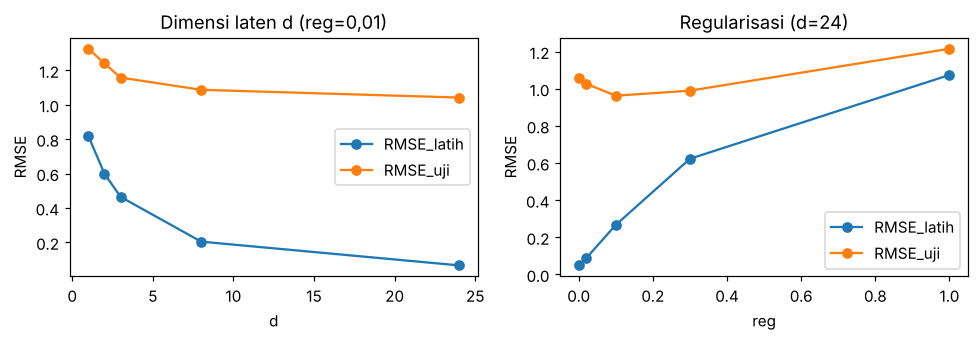

In [4]:
rows = []
for reg in (0.0, 0.02, 0.1, 0.3, 1.0):
    m_ = BiasedMF(d=24, lr=0.02, reg=reg, epochs=60, seed=0).fit(R_latih)
    rows.append({"reg": reg, "RMSE_latih": rmse_mf(m_, latih, Rs), "RMSE_uji": rmse_mf(m_, uji, Rs)})
hasil_reg = pd.DataFrame(rows).set_index("reg")
print(hasil_reg.round(3))

fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.2))
hasil_d.plot(ax=a, marker="o", title="Dimensi laten d (reg=0,01)")
hasil_reg.plot(ax=b, marker="o", logx=False, title="Regularisasi (d=24)")
for x in (a, b): x.set_ylabel("RMSE")
fig.tight_layout()

# klaim yang diuji: galat latih lebih kecil daripada galat uji (celah generalisasi)
assert (hasil_d["RMSE_uji"] > hasil_d["RMSE_latih"]).all()

**Interpretasi (data simulasi).** Galat latih lebih kecil daripada galat uji di semua konfigurasi, dan celahnya melebar saat model makin ekspresif: pada *d* = 24 model nyaris hafal data latih (galat ≈ 0,07) tetapi galat uji tetap sekitar 1,0. Pada eksperimen ini galat uji tidak naik tajam bersama *d*, karena pelatihan hanya 60 epoch dengan inisialisasi kecil (efek *early stopping*). Regularisasi menunjukkan bentuk U: tanpa regularisasi model menghafal, sedangkan `reg` terlalu besar membuat model *underfit* (galat latih dan uji sama-sama naik). Titik terbaik ada di nilai menengah.

## 4. Eksperimen C: lamanya pelatihan

Latih model besar tanpa regularisasi dengan jumlah epoch yang makin banyak.

In [5]:
rows = []
for ep in (5, 20, 60, 150, 400):
    m_ = BiasedMF(d=24, lr=0.02, reg=0.0, epochs=ep, seed=0).fit(R_latih)
    rows.append({"epochs": ep, "RMSE_latih": rmse_mf(m_, latih, Rs), "RMSE_uji": rmse_mf(m_, uji, Rs)})
hasil_ep = pd.DataFrame(rows).set_index("epochs")
print(hasil_ep.round(3))
assert hasil_ep["RMSE_latih"].is_monotonic_decreasing
assert hasil_ep["RMSE_uji"].idxmin() not in (hasil_ep.index[0], hasil_ep.index[-1])

        RMSE_latih  RMSE_uji
epochs                      
5            1.003     1.214
20           0.376     1.088
60           0.049     1.060
150          0.003     1.070
400          0.000     1.070


**Interpretasi.** Galat latih turun terus hingga hampir nol, sedangkan galat uji mencapai titik terendah di epoch menengah lalu sedikit naik. Itulah alasan praktiknya memakai data validasi untuk menghentikan pelatihan lebih awal (*early stopping*), bukan melatih sampai galat latih habis.

## Pertanyaan refleksi

1. Mengapa pembaruan `bu`, `bi`, `P`, `Q` memakai salinan `pu` sebelum diperbarui?
2. Apa yang berubah jika `epochs` dinaikkan dari 60 menjadi 300 pada konfigurasi `d=24, reg=0.01`?
3. Mengapa SGD per rating sulit diparalelkan, dan apa alternatifnya? (Lihat ALS di Bab 4.)